In [1]:
import sys 
from pathlib import Path

root =  Path.cwd().parent
sys.path.append(str(root))

from src.data.load import ImageLoader
from src.data.visualize import Painter
from src.data.preprocess import Processor

import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

loader =  ImageLoader()

images, labels, classes = loader.loadImages()

I0000 00:00:1791927160.043077  212180 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791927160.043786  212180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791927160.105546  212180 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791927161.780707  212180 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

class: glioma containes 1621 files
class: meningioma containes 1645 files
class: notumor containes 2000 files
class: pituitary containes 1757 files
Loaded images: (7023, 224, 224, 3)
Loaded labels: (7023,)
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [2]:
images, labels  = Processor.shuffleData(images, labels)

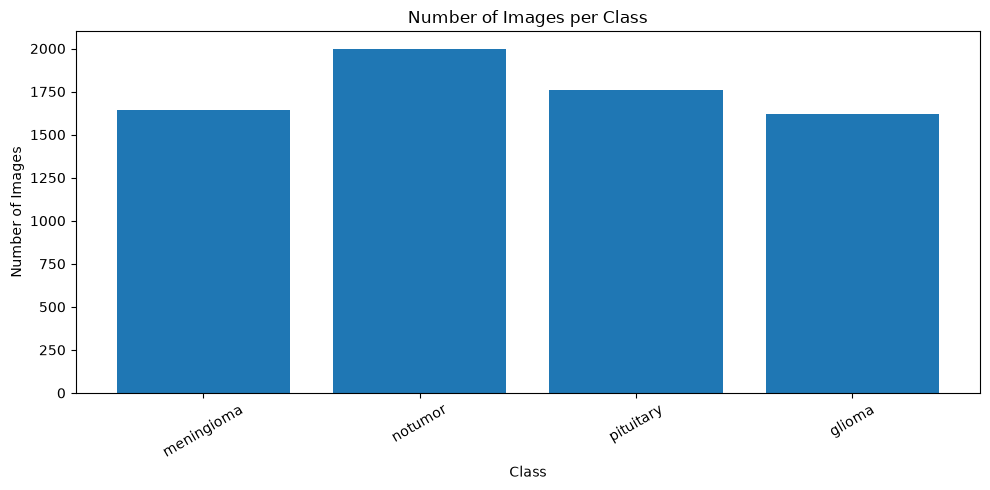

In [3]:
Painter.drawBarPlt(
    labels,
    "Number of Images per Class",
    "Class",
    "Number of Images")

In [4]:


encoder, labels_encoded = Processor.encodeLabels(labels)

Classes: ['glioma' 'meningioma' 'notumor' 'pituitary']
Encoded labels: [1 2 3 2 3 0 3 1 0 1]


In [5]:
x_train, x_test, y_train, y_test = train_test_split(
    images,
    labels_encoded,
    test_size=0.30,
    random_state=42,
    stratify=labels_encoded,
)

In [6]:
y_train_cat, y_test_cat = Processor.encodeTarget(encoder, y_train, y_test)

y_train_cat: (4916, 4)
y_test_cat: (2107, 4)
Example: 0 -> [1. 0. 0. 0.]


In [7]:
X_train , X_test = Processor.scaleData(x_train, x_test)


In [8]:
print("Train:", X_train.shape, y_train_cat.shape)
print("Test:", X_test.shape, y_test_cat.shape)
print("Pixel range:", X_train.min(), X_train.max())
print("Label values:", set(y_train))


Train: (4916, 224, 224, 3) (4916, 4)
Test: (2107, 224, 224, 3) (2107, 4)
Pixel range: 0.0 1.0
Label values: {np.int64(0), np.int64(1), np.int64(2), np.int64(3)}


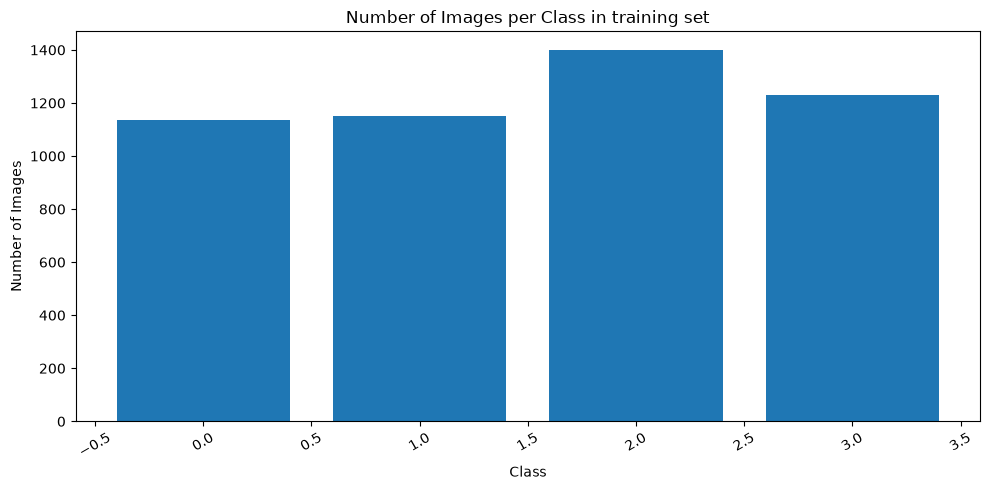

In [9]:
Painter.drawBarPlt(
    y_train,
    "Number of Images per Class in training set",
    "Class",
    "Number of Images")

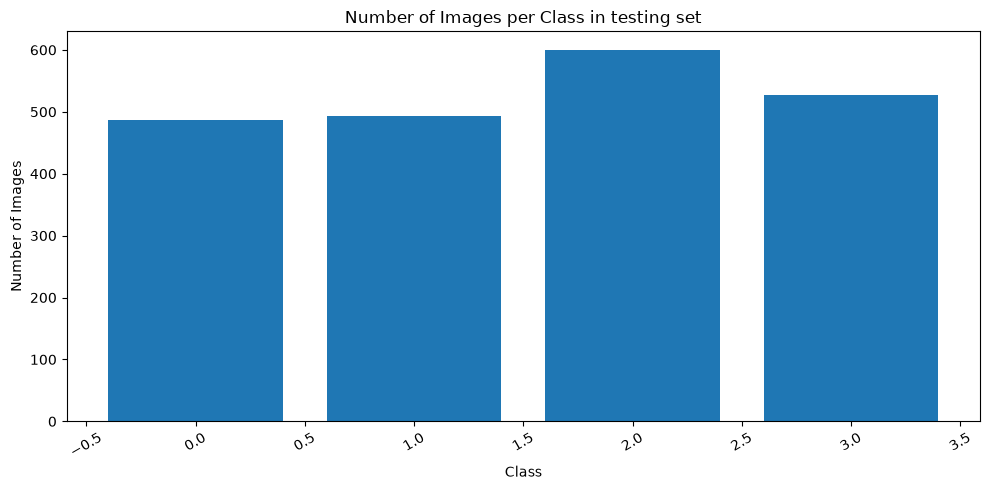

In [10]:
Painter.drawBarPlt(
    y_test,
    "Number of Images per Class in testing set",
    "Class",
    "Number of Images")

In [12]:
Processor.saveData(encoder, X_train, y_train, X_test, y_test, y_train_cat, y_test_cat)